In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [121]:
class DynamicGraph(nn.Module):
    def __init__(self, feature_dim=64, max_nodes=1024, max_edges_per_node=8, input_size=64, output_size=2, hidden_layers=[128, 256, 256, 128, 64], device=None):
        super().__init__()
        if device==None:
            if hasattr(torch, "xpu") and torch.xpu.is_available():
                device = torch.device("xpu")
            elif torch.cuda.is_available():
                device = torch.device("cuda")
            else:
                device = torch.device("cpu")
        self.device = torch.device(device)
        print(f"\nUsing device : {device}\n")

        self.D = feature_dim
        self.max_nodes = max_nodes
        self.max_edges = max_nodes * max_edges_per_node
        # max_edges = self.max_edges
        self.max_edges_per_node = max_edges_per_node
        self.input_size = input_size
        self.output_size = output_size
        self.hidden_layers = hidden_layers
        self.max_rank = len(hidden_layers)

        ## Node Thingys

        # Node Weights (no_of_nodes,1)
        self.node_weight = nn.Parameter(
            torch.zeros(
                max_nodes,
                feature_dim,
                device=self.device
            )
        )

        # Node Pre Activation(Input of current node) (no_of_nodes,1)
        self.register_buffer(
            "node_pre_activation",
            torch.zeros(
                max_nodes,
                feature_dim,
                dtype=torch.float32,
                device=self.device
            )
        )

        # Node Activation(Input of current node) (no_of_nodes,1)
        self.register_buffer(
            "node_activation",
            torch.zeros(
                max_nodes,
                feature_dim,
                dtype=torch.float32,
                device=self.device
            )
        )

        # Node Bias (no_of_nodes,1)
        self.node_bias = nn.Parameter(
            torch.randn(
                max_nodes,
                feature_dim,
                device=self.device
            ) * 0.02
        )

        # Node Active/Deactive (no_of_nodes,1)
        self.register_buffer(
            "node_alive",
            torch.zeros(
                max_nodes,
                dtype=torch.bool,
                device=self.device
            )
        )

        # Node Activation Type (Relu/Sigmoid/LRelu) (no_of_nodes,1)
        self.register_buffer(
            "node_activation_type",
            torch.zeros(
                max_nodes,
                dtype=torch.long,
                device=self.device
            )   
        )

        # Node Out Degree (no_of_nodes,1) (Value ranges from 0 to max_edges_per_node)
        self.register_buffer(
            "out_degree",
            torch.zeros(
                max_nodes,
                dtype=torch.long,
                device=self.device
            )
        )

        # Node In Degree (no_of_nodes,1) (Value ranges from 0 to no_of_nodes * max_edges_per_node)
        self.register_buffer(
            "in_degree",
            torch.zeros(
                max_nodes,
                dtype=torch.long,
                device=self.device
            )
        )

        # Node Rank (no_of_nodes,1)
        # Used to store the rank of nodes, which is used to prevent cycles
        self.register_buffer(
            "node_rank",
            torch.zeros(
                max_nodes,
                dtype=torch.long,
                device=self.device
            )
        )

        # No of current nodes (Includes Active + Deactive)
        self.nodes_count = 0


        ## Edge Thingys

        # Edge Source[edge_source][index] = edge_destination (no_of_nodes,max_edges_per_node)
        self.register_buffer(
            "edge_src",
            -1*torch.ones(
                max_nodes,
                max_edges_per_node,
                dtype=torch.long,
                device=self.device
            )
        )

        # Edge Index[edge_destination][index] = edge_source (no_of_nodes,max_edges_per_node)
        # Used to store the index of edge stored in edge_src matrix for quick operation in back prop
        self.register_buffer(
            "edge_index",
            -1*torch.ones(
                max_nodes,
                max_edges_per_node,
                dtype=torch.long,
                device=self.device
            )
        )

        # Edge Destination[edge_destination][index] = edge_source (no_of_nodes,max_edges_per_node)
        self.register_buffer(
            "edge_dest",
            -1*torch.ones(
                max_nodes,
                max_edges_per_node,
                dtype=torch.long,
                device=self.device
            )
        )

        # Edge Weight[edge_source][edge_destination] (no_of_nodes,max_edges_per_node)
        self.edge_weight = nn.Parameter(
            torch.randn(
                max_nodes,
                max_edges_per_node,
                device=self.device
            ) * 0.02
        )

        # Edge Active/Deactive[edge_source][edge_destination] (no_of_nodes,max_edges_per_node)
        self.register_buffer(
            "edge_alive",
            torch.zeros(
                max_nodes,
                max_edges_per_node,
                dtype=torch.bool,
                device=self.device
            )   
        )

    @torch.no_grad()
    def add_node(self, activation=1):
        if self.nodes_count >= self.max_nodes:
            raise RuntimeError("Node capacity reached in Add Node"+str(self.max_nodes))
        index = self.nodes_count
        self.node_alive[index] = True
        self.node_activation_type[index] = activation
        self.nodes_count += 1
        return index

    @torch.no_grad()
    def remove_node(self, index):
        if index>=self.nodes_count or index<0:
            raise RuntimeError("Out of bound in Remove Node")

        self.node_alive[index] = False

    @torch.no_grad()
    def add_edge(self, source, destination):
        if source<0 or source>=self.nodes_count or destination<0 or destination>=self.nodes_count:
            raise RuntimeError("Out of bound in Add Edge 1st Thingy")
        if self.out_degree[source]>=self.max_edges_per_node or self.in_degree[destination]>=self.max_edges_per_node:
            raise RuntimeError("Out of bound in Add Edge 2nd Thingy")
        self.edge_src[source][self.out_degree[source]] = destination

        self.edge_index[destination][self.in_degree[destination]] = self.out_degree[source]
        self.edge_dest[destination][self.in_degree[destination]] = source

        self.edge_alive[source][self.out_degree[source]] = True

        self.out_degree[source] += 1
        self.in_degree[destination] += 1

    @torch.no_grad()
    def remove_edge(self, source, destination):
        if source<0 or source>=self.nodes_count or destination<0 or destination>=self.nodes_count:
            raise RuntimeError("Out of bound in Remove Edge")
        temp_index = self.edge_src[source]==destination
        self.edge_alive[source][temp_index] = False

    @torch.no_grad()
    def random_sample_source(self, start_index, end_index, target_size, destination_idx=None):
        source_idx = torch.zeros(target_size,dtype=torch.long,device=self.device)
        temp_idx = torch.arange(0,self.max_nodes,1,device=self.device)

        temp_idx = temp_idx[start_index:end_index][self.in_degree[start_index:end_index]<self.max_edges_per_node-1]
        
        temp_idx = temp_idx[torch.randperm(len(temp_idx))]
        source_idx[:min(len(temp_idx),target_size)] = temp_idx[:target_size]

        start, end = 0, min(len(temp_idx),target_size)
        self.edge_src[source_idx[start: end], self.out_degree[source_idx[start: end]]] = destination_idx[start: end]
        self.edge_index[destination_idx[start: end], self.in_degree[destination_idx[start: end]]] = self.out_degree[source_idx[start: end]]
        self.edge_dest[destination_idx[start: end], self.in_degree[destination_idx[start: end]]] = source_idx[start: end]
        self.out_degree[source_idx[start: end]] += 1
        self.in_degree[destination_idx[start: end]] += 1
        
        current_size = min(len(temp_idx),target_size)
        current_target_size = target_size - current_size
        while current_size!=target_size:
            if current_size==0:
                print("Can't Initialize as no of nodes in some rank isn't enough, Please increase no of nodes appropriately!!")
                raise RuntimeError("Can't Initialize as no of nodes in some rank isn't enough, Please increase no of nodes appropriately!!")
            
            temp_idx = torch.arange(0,self.max_nodes,1,device=self.device)

            temp_idx = temp_idx[start_index:end_index][self.in_degree[start_index:end_index]<self.max_edges_per_node-1]
            
            temp_idx = temp_idx[torch.randperm(len(temp_idx))]
            if len(temp_idx) == 0:
                print("Can't Initialize as max edges per node isn't enough, Please increase max edges per node accordingly!!")
                raise RuntimeError("Can't Initialize as max edges per node isn't enough, Please increase max edges per node accordingly!!")
            start, end = current_size, current_size + min(current_target_size,len(temp_idx))
            source_idx[start: end] = temp_idx[:current_target_size]

            

            self.edge_src[destination_idx[start: end], self.out_degree[destination_idx[start: end]]] = source_idx[start: end]
            self.edge_index[source_idx[start: end], self.in_degree[source_idx[start: end]]] = self.out_degree[destination_idx[start: end]]
            self.edge_dest[source_idx[start: end], self.in_degree[source_idx[start: end]]] = destination_idx[start: end]
            self.out_degree[destination_idx[start: end]] += 1
            self.in_degree[source_idx[start: end]] += 1

            current_size += min(current_target_size,len(temp_idx))
            current_target_size = target_size - current_size
            
        return source_idx
    
    @torch.no_grad()
    def random_sample_destination(self, start_index, end_index, target_size, source_idx=None):
        destination_idx = torch.zeros(target_size,dtype=torch.long,device=self.device)
        temp_idx = torch.arange(0,self.max_nodes,1,device=self.device)

        temp_idx = temp_idx[start_index:end_index][self.in_degree[start_index:end_index]<self.max_edges_per_node-1]
        
        temp_idx = temp_idx[torch.randperm(len(temp_idx))]
        destination_idx[:min(len(temp_idx),target_size)] = temp_idx[:target_size]

        start, end = 0, min(len(temp_idx),target_size)
        self.edge_src[source_idx[start: end], self.out_degree[source_idx[start: end]]] = destination_idx[start: end]
        self.edge_index[destination_idx[start: end], self.in_degree[destination_idx[start: end]]] = self.out_degree[source_idx[start: end]]
        self.edge_dest[destination_idx[start: end], self.in_degree[destination_idx[start: end]]] = source_idx[start: end]
        self.out_degree[source_idx[start: end]] += 1
        self.in_degree[destination_idx[start: end]] += 1
        
        current_size = min(len(temp_idx),target_size)
        current_target_size = target_size - current_size
        while current_size!=target_size:
            if current_size==0:
                print("Can't Initialize as no of nodes in some rank isn't enough, Please increase no of nodes appropriately!!")
                raise RuntimeError("Can't Initialize as no of nodes in some rank isn't enough, Please increase no of nodes appropriately!!")
            
            temp_idx = torch.arange(0,self.max_nodes,1,device=self.device)

            temp_idx = temp_idx[start_index:end_index][self.in_degree[start_index:end_index]<self.max_edges_per_node-1]
            
            temp_idx = temp_idx[torch.randperm(len(temp_idx))]
            if len(temp_idx) == 0:
                print("Can't Initialize as max edges per node isn't enough, Please increase max edges per node accordingly!!")
                raise RuntimeError("Can't Initialize as max edges per node isn't enough, Please increase max edges per node accordingly!!")
            start, end = current_size, current_size + min(current_target_size,len(temp_idx))
            destination_idx[start: end] = temp_idx[:current_target_size]

            

            self.edge_src[source_idx[start: end], self.out_degree[source_idx[start: end]]] = destination_idx[start: end]
            self.edge_index[destination_idx[start: end], self.in_degree[destination_idx[start: end]]] = self.out_degree[source_idx[start: end]]
            self.edge_dest[destination_idx[start: end], self.in_degree[destination_idx[start: end]]] = source_idx[start: end]
            self.out_degree[source_idx[start: end]] += 1
            self.in_degree[destination_idx[start: end]] += 1

            current_size += min(current_target_size,len(temp_idx))
            current_target_size = target_size - current_size
            
        return destination_idx

    ## Note: This Initialize Graph method can create edges between the same pair of nodes multiple times too.
    @torch.no_grad()
    def initialize_graph(self):
        total_layers = sum(self.hidden_layers)
        if total_layers>self.max_nodes:
            raise RuntimeError("More no of hidden thingys in Initialize Graph")
        
        current_count = 0
        temp_layers = self.hidden_layers.copy()
        print(temp_layers)
        output_layer_count = temp_layers.pop()
        print(temp_layers)
        for i in range(len(temp_layers)):
            layer_count = temp_layers[i]
            self.node_activation_type[current_count:current_count+layer_count] = 1
            self.node_rank[current_count:current_count+layer_count] = i+1
            current_count += layer_count
        self.node_activation_type[current_count:current_count+output_layer_count] = 2
        self.node_rank[current_count:current_count+output_layer_count] = len(self.hidden_layers)
        self.node_alive[:total_layers] = True
        self.nodes_count = total_layers

        current_count = 0
        for i in range(len(self.hidden_layers)-1):
            source_idx = torch.randperm(
                self.hidden_layers[i],
                device=self.device
            )
            source_idx += current_count

            destination_idx = self.random_sample_destination(
                self.hidden_layers[i]+current_count,
                total_layers,
                self.hidden_layers[i],
                source_idx=source_idx
            )
            current_count += self.hidden_layers[i]
            
        current_count = self.hidden_layers[0]
        for i in range(1,len(self.hidden_layers)):
            destination_idx = torch.randperm(
                self.hidden_layers[i],
                device=self.device
            )
            destination_idx += current_count
            print(destination_idx)

            source_idx = self.random_sample_source(
                0,
                current_count,
                self.hidden_layers[i],
                destination_idx=destination_idx
            )
            current_count += self.hidden_layers[i]

    def forward(self, x):
        self.node_pre_activation = self.node_pre_activation.detach()
        self.node_activation = self.node_activation.detach()
        rank_1_mask = (self.node_rank==1) & self.node_alive
        self.node_pre_activation[rank_1_mask] = x * self.node_weight[rank_1_mask] + self.node_bias[rank_1_mask]
        self.node_activation[rank_1_mask] = apply_activation(self.node_pre_activation[rank_1_mask],self.node_activation_type[rank_1_mask])
        n = len(self.edge_src)
        m = len(self.edge_src[0])
        temp_src_matrix = torch.arange(n, device=self.node_weight.device).unsqueeze(1).expand(n, m)
        temp_src_index = torch.arange(m, device=self.node_weight.device).repeat(n,1)
        for rank in range(2,self.max_rank+1):
            current_mask = (self.node_rank==rank) & self.node_alive
            prev_mask = (self.node_rank==(rank-1)) & self.node_alive
            self.node_pre_activation[current_mask] = 0
            # node_pre_activation[node_rank==rank] = node_pre_activation[node_rank==rank-1] * node_weight[node_rank==rank] + node_bias[node_rank==rank]
            valid_edges = self.edge_alive & prev_mask.unsqueeze(1)
            temp_src = temp_src_matrix[valid_edges]
            temp_index = temp_src_index[valid_edges]
            temp_dest = self.edge_src[valid_edges]
            self.node_pre_activation.index_add_(0,temp_dest,self.node_activation[temp_src]*self.edge_weight[temp_src, temp_index].unsqueeze(1) * self.node_weight[temp_dest])
            self.node_pre_activation[current_mask] += self.node_bias[current_mask]
            self.node_activation[current_mask] = apply_activation(self.node_pre_activation[current_mask],self.node_activation_type[current_mask])

        output = self.node_activation[(self.node_rank==self.max_rank) & self.node_alive]
        output = output.mean(dim=1)
        return output

    
    


In [37]:
def apply_activation(x, activation_type):

    output = torch.empty_like(x)

    # ReLU
    mask = activation_type == 0
    output[mask] = torch.relu(x[mask])

    # Sigmoid
    mask = activation_type == 1
    output[mask] = torch.sigmoid(x[mask])

    # Leaky ReLU
    mask = activation_type == 2
    output[mask] = torch.nn.functional.leaky_relu(
        x[mask],
        negative_slope=0.01
    )

    # Tanh
    mask = activation_type == 3
    output[mask] = torch.tanh(x[mask])

    # No activation
    mask = activation_type == 4
    output[mask] = x[mask]

    return output

In [10]:
class MyFunction(torch.autograd.Function):

    @staticmethod
    def forward(ctx, node_activation, node_activation_type, node_pre_activation, x, edge_src, edge_dest, node_rank, max_rank, edge_index, node_weight, node_bias, edge_weight, edge_alive, node_alive):
        rank_1_mask = (node_rank==1) & node_alive
        node_pre_activation[rank_1_mask] = x * node_weight[rank_1_mask] + node_bias[rank_1_mask]
        node_activation[rank_1_mask] = apply_activation(node_pre_activation[rank_1_mask],node_activation_type[rank_1_mask])
        n = len(edge_src)
        m = len(edge_src[0])
        temp_src_matrix = torch.arange(n, device=node_weight.device).unsqueeze(1).expand(n, m)
        temp_src_index = torch.arange(m, device=node_weight.device).repeat(n,1)
        for rank in range(2,max_rank+1):
            current_mask = (node_rank==rank) & node_alive
            prev_mask = (node_rank==(rank-1)) & node_alive
            node_pre_activation[current_mask] = 0
            # node_pre_activation[node_rank==rank] = node_pre_activation[node_rank==rank-1] * node_weight[node_rank==rank] + node_bias[node_rank==rank]
            valid_edges = edge_alive & prev_mask.unsqueeze(1)
            temp_src = temp_src_matrix[valid_edges]
            temp_index = temp_src_index[valid_edges]
            temp_dest = edge_src[valid_edges]
            node_pre_activation.index_add_(0,temp_dest,node_activation[temp_src]*edge_weight[temp_src, temp_index] * node_weight[temp_dest])
            node_pre_activation[current_mask] += node_bias[current_mask]
            node_activation[current_mask] = apply_activation(node_pre_activation[current_mask],node_activation_type[current_mask])

        output = node_activation[(node_rank==max_rank) & node_alive]

        ctx.max_rank = max_rank
        ctx.save_for_backward(
            x, 
            node_activation, 
            node_activation_type, 
            node_pre_activation, 
            edge_src, 
            edge_dest, 
            node_rank, 
            edge_index, 
            node_weight, 
            node_bias, 
            edge_weight, 
            edge_alive, 
            node_alive
        )

        return output

    @staticmethod
    def backward(ctx, grad_output):
        # calculate gradients
        return gradients

tensor([2, 3, 1, 4, 0])

In [11]:
# temp = DynamicGraph(2,10,2)
temp = DynamicGraph(2,1024)
# node0 = temp.add_node()
# node1 = temp.add_node()
# node2 = temp.add_node()

# temp.add_edge(node0,node2)
# temp.add_edge(node0,node1)
# temp.remove_edge(node0,node2)

# temp.remove_node(node1)

print(temp.node_alive)



Using device : xpu

tensor([False, False, False,  ..., False, False, False], device='xpu:0')


In [12]:
# # print(temp.in_degree[130:])
# temp = DynamicGraph(2,1024)
# temp.initialize_graph()
# temp1 = temp.node_rank
# print(temp1)

In [13]:
import torch
import networkx as nx
import matplotlib.pyplot as plt


def visualize_edge_src(edge_src, hidden_layers):
    """
    Visualize edge_src as an adjacency-list graph.

    Parameters
    ----------
    edge_src : torch.Tensor
        Shape: [num_nodes, max_edges_per_node]
        edge_src[source, i] = destination
        -1 means no edge.

    hidden_layers : list[int]
        Number of nodes in each layer.

        Example:
            [5, 5, 5, 3]

        means:

            Layer 1: nodes 0  - 4
            Layer 2: nodes 5  - 9
            Layer 3: nodes 10 - 14
            Layer 4: nodes 15 - 17
    """

    edge_src = edge_src.detach().cpu()

    G = nx.DiGraph()

    # --------------------------------------------------
    # Create edges
    # --------------------------------------------------

    for source in range(edge_src.shape[0]):

        for destination in edge_src[source]:

            destination = destination.item()

            # Ignore unused entries
            if destination == -1:
                continue

            G.add_edge(source, destination)

    # --------------------------------------------------
    # Create positions based on hidden_layers
    # --------------------------------------------------

    pos = {}

    current_node = 0

    # Space between layers
    layer_spacing = 3.0

    # Create each layer
    for layer, num_nodes in enumerate(hidden_layers):

        x = layer * layer_spacing

        # Center nodes vertically
        y_start = (num_nodes - 1) / 2

        for i in range(num_nodes):

            node = current_node + i

            y = y_start - i

            pos[node] = (x, y)

        current_node += num_nodes

    # --------------------------------------------------
    # Draw
    # --------------------------------------------------

    plt.figure(figsize=(12, 8))

    nx.draw(
        G,
        pos,
        with_labels=True,
        node_size=1200,
        arrows=True,
        arrowsize=20,
        font_size=10
    )

    # --------------------------------------------------
    # Draw layer labels
    # --------------------------------------------------

    current_node = 0

    for layer, num_nodes in enumerate(hidden_layers):

        x = layer * layer_spacing

        # Middle of this layer
        y = 0

        if num_nodes > 0:
            y = (num_nodes - 1) / 2 + 1.0

        plt.text(
            x,
            y,
            f"Layer {layer + 1}",
            ha="center",
            fontsize=12
        )

        current_node += num_nodes

    plt.title("DynamicGraph - edge_src")
    plt.axis("off")
    plt.tight_layout()
    plt.show()


Using device : xpu

[2, 3, 3, 1]
[2, 3, 3]
tensor([3, 4, 2], device='xpu:0')
tensor([7, 6, 5], device='xpu:0')
tensor([8], device='xpu:0')
tensor([1, 1, 2, 2, 2, 3, 3, 3, 4, 0], device='xpu:0')
8
tensor([[ 7,  4, -1, -1, -1, -1, -1, -1],
        [ 8,  3, -1, -1, -1, -1, -1, -1],
        [ 8,  1,  5, -1, -1, -1, -1, -1],
        [ 7,  7, -1, -1, -1, -1, -1, -1],
        [ 5,  6,  8, -1, -1, -1, -1, -1],
        [ 8, -1, -1, -1, -1, -1, -1, -1],
        [ 8, -1, -1, -1, -1, -1, -1, -1],
        [ 8, -1, -1, -1, -1, -1, -1, -1],
        [-1, -1, -1, -1, -1, -1, -1, -1],
        [-1, -1, -1, -1, -1, -1, -1, -1]], device='xpu:0')
Edge Dest
 tensor([], device='xpu:0', size=(0, 8), dtype=torch.int64)


/tmp/ipykernel_24220/1415885533.py:124: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


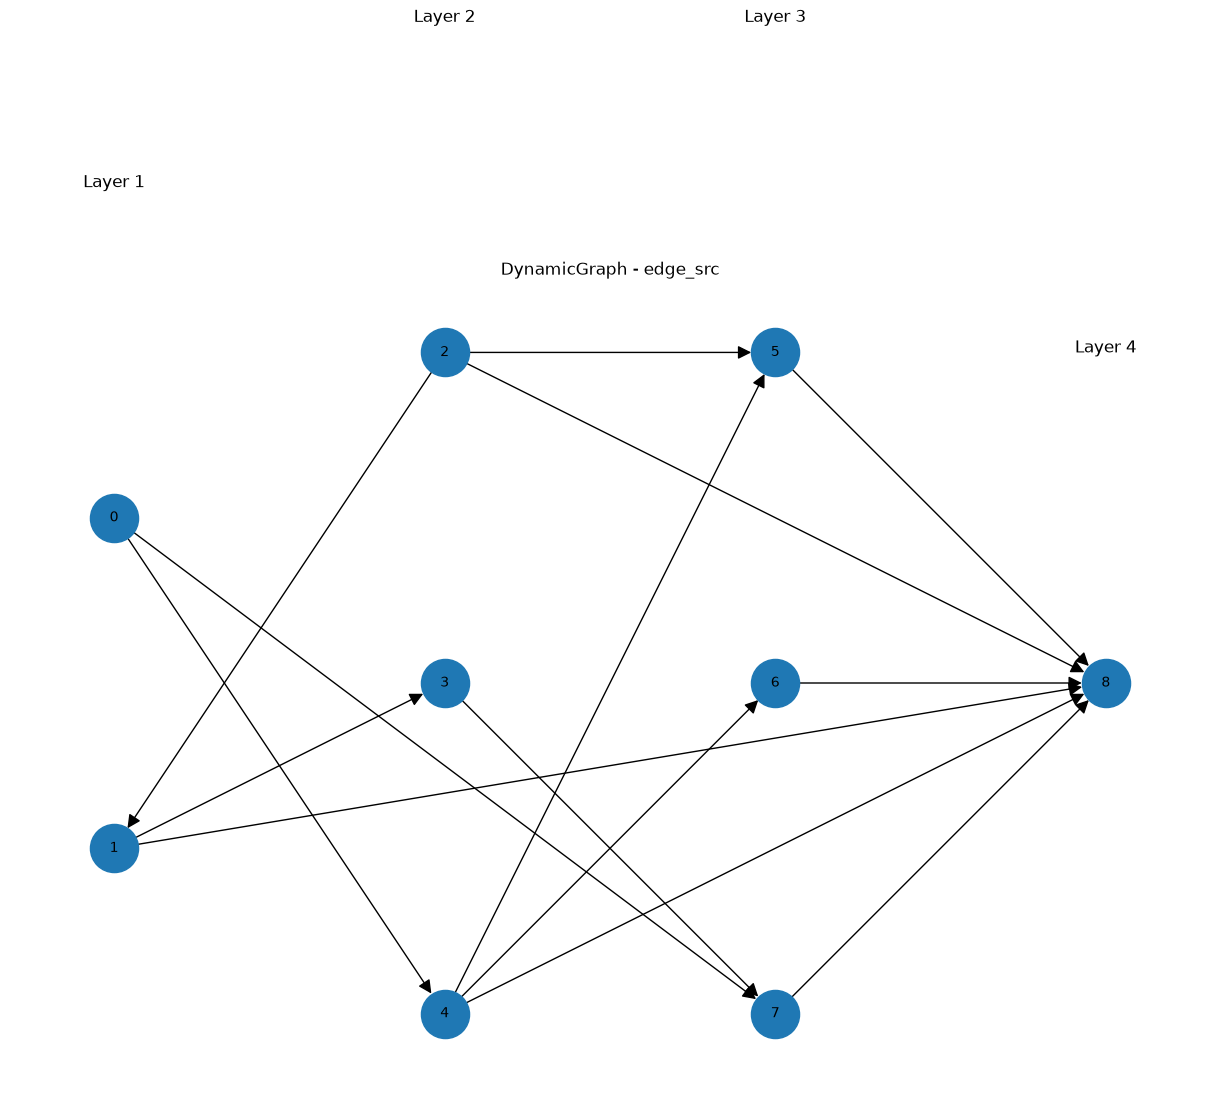

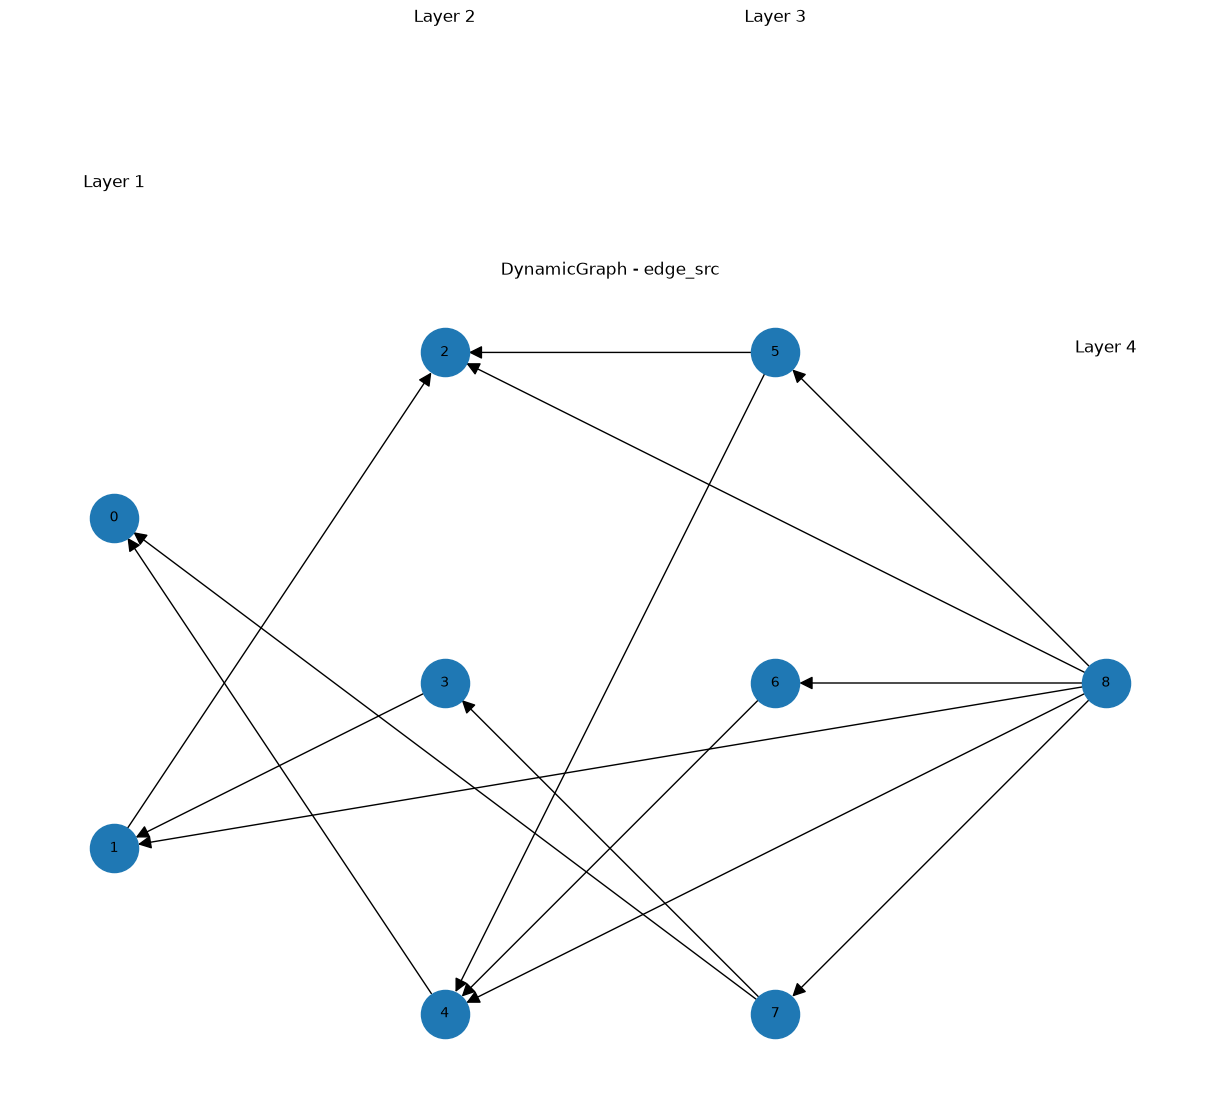

In [139]:
# print(temp.in_degree[130:])
hidden_layers = [2,3,3,1]
temp = DynamicGraph(2,10,hidden_layers=hidden_layers,max_edges_per_node=8,device="xpu")
# temp = DynamicGraph(2,device="xpu")
temp.initialize_graph()
temp1 = temp.node_rank
print(temp1)
print(temp.max_edges_per_node)
print(temp.edge_src)
# print("Edge Src\n",temp.edge_src)
print("Edge Dest\n",temp.edge_dest[25000-1:])
# print("temp",temp.edge_src.reshape(-1).shape)
# print("Indegree",temp.in_degree)
# print("Outdegree",temp.out_degree)
visualize_edge_src(temp.edge_src,hidden_layers)
visualize_edge_src(temp.edge_dest,hidden_layers)

In [130]:
# from PIL import Image
# from torchvision import transforms
# from torch.utils.data import TensorDataset, DataLoader

# device = torch.device("xpu")

# img = Image.open("GAN Images/class1_1.png").convert("RGB")

# # [3, H, W] -> [H, W, 3] -> [H*W, 3]
# pixels = (
#     transforms.ToTensor()(img)
#     .permute(1, 2, 0)
#     .reshape(-1, 3)
# )

# print("Pixels:", pixels.shape)

# # One image, one arbitrary label
# # Add image dimension: [1, H*W, 3]
# images = pixels.unsqueeze(0)

# # One label: [1]
# labels = torch.tensor([0], dtype=torch.long)

# dataset = TensorDataset(images, labels)

# train_loader = DataLoader(
#     dataset,
#     batch_size=1,
#     shuffle=True
# )
"""
from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
import os
import torch

device = torch.device("xpu")

transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])


class ImageDataset(Dataset):

    def __init__(self, image_dir, count=1000):
        self.image_dir = image_dir

        files = [
            os.path.join(image_dir, f)
            for f in os.listdir(image_dir)
            if f.lower().endswith((".png", ".jpg", ".jpeg"))
        ]

        self.files = files[:count]

        if len(self.files) < count:
            raise RuntimeError(
                f"Only found {len(self.files)} images, "
                f"but requested {count}"
            )

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):

        img = Image.open(self.files[idx]).convert("RGB")

        # [3, 64, 64]
        img = transform(img)

        # [4096, 3]
        pixels = img.permute(1, 2, 0).reshape(-1, 3)

        # Dummy label for now
        label = torch.tensor(0, dtype=torch.long)

        return pixels, label


dataset = ImageDataset(
    "GAN Images",
    count=1000
)

train_loader = DataLoader(
    dataset,
    batch_size=1,
    shuffle=True
)

print("Images:", len(dataset))

# for x, y in train_loader:
#     print("x:", x.shape)
#     print("y:", y.shape)
#     break

"""

import torch
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("xpu")

# 1000 random RGB images
# [1000, 64, 64, 3]
images = torch.rand(
    1000, 64, 64, 3
)

# Convert to [1000, 4096, 3]
images = images.reshape(1000, 4096, 3)

# Dummy labels
labels = torch.zeros(
    1000,
    dtype=torch.long
)

dataset = TensorDataset(images, labels)

train_loader = DataLoader(
    dataset,
    batch_size=1,
    shuffle=True
)

print("Images :", images.shape)
print("Labels :", labels.shape)

# Test
x, y = next(iter(train_loader))

print("Batch x:", x.shape)  # [1, 4096, 3]
print("Batch y:", y.shape)  # [1]

device = (
    torch.device("xpu") if hasattr(torch, "xpu") and torch.xpu.is_available()
    else torch.device("cuda") if torch.cuda.is_available()
    else torch.device("cpu")
)

model = DynamicGraph(
    feature_dim=3,
    max_nodes=50000,
    max_edges_per_node=20,
    input_size=4096,
    output_size=43,
    hidden_layers=[4096, 3000, 1500, 100],
    device=device
).to(device)

model.initialize_graph()

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

epochs = 20

for epoch in range(epochs):

    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for x, y in train_loader:

        x = x.to(device)
        y = y.to(device)

        # Your current forward handles ONE sample
        for i in range(x.size(0)):

            optimizer.zero_grad()
            

            output = model(x[i])

            # output should be [43]
            loss = criterion(
                output.unsqueeze(0),
                y[i].unsqueeze(0)
            )

            loss.backward()

            optimizer.step()

            total_loss += loss.item()

            prediction = output.argmax()

            correct += (prediction == y[i]).item()
            total += 1

    accuracy = 100.0 * correct / total

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {total_loss/total:.4f} "
        f"Accuracy: {accuracy:.2f}%"
    )

Images : torch.Size([1000, 4096, 3])
Labels : torch.Size([1000])
Batch x: torch.Size([1, 4096, 3])
Batch y: torch.Size([1])

Using device : xpu

[4096, 3000, 1500, 100]
[4096, 3000, 1500]
tensor([5581, 6062, 6224,  ..., 6878, 4968, 4402], device='xpu:0')
tensor([8116, 7764, 7800,  ..., 7718, 7772, 7755], device='xpu:0')
tensor([8649, 8693, 8645, 8650, 8617, 8614, 8625, 8626, 8628, 8682, 8637, 8605,
        8630, 8647, 8660, 8684, 8671, 8599, 8643, 8624, 8678, 8597, 8620, 8656,
        8689, 8601, 8640, 8677, 8616, 8602, 8619, 8690, 8613, 8674, 8600, 8610,
        8667, 8622, 8665, 8634, 8652, 8663, 8598, 8694, 8648, 8615, 8629, 8653,
        8669, 8638, 8688, 8633, 8627, 8657, 8691, 8609, 8683, 8672, 8603, 8670,
        8646, 8664, 8681, 8680, 8654, 8639, 8621, 8631, 8675, 8676, 8668, 8658,
        8679, 8641, 8692, 8686, 8623, 8662, 8636, 8604, 8666, 8673, 8611, 8695,
        8687, 8661, 8606, 8607, 8644, 8655, 8685, 8612, 8608, 8632, 8651, 8659,
        8642, 8618, 8635, 8596], devic

KeyboardInterrupt: 

In [142]:
import torch
from torch.utils.data import TensorDataset, DataLoader
from tqdm.auto import tqdm

device = torch.device("xpu")

# 1000 random 64x64 RGB images
no_of_images = 1000
images = torch.rand(no_of_images, 4096, 3)
labels = torch.zeros(no_of_images, dtype=torch.long)

dataset = TensorDataset(images, labels)

train_loader = DataLoader(
    dataset,
    batch_size=1,
    shuffle=True
)

# ---------------- MODEL ----------------

model = DynamicGraph(
    feature_dim=3,
    max_nodes=50000,
    max_edges_per_node=20,
    input_size=4096,
    output_size=43,
    hidden_layers=[4096, 3000, 1500, 100],
    device=device
).to(device)

model.initialize_graph()

criterion = torch.nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

# ---------------- TRAIN ----------------

epochs = 20
from tqdm.auto import tqdm
import time

for epoch in range(epochs):

    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    progress = tqdm(
        train_loader,
        total=len(train_loader),
        desc=f"Epoch {epoch+1}/{epochs}",
        unit="img",
        dynamic_ncols=True
    )

    start_time = time.perf_counter()

    for x, y in progress:

        x = x[0].to(device)   # [4096, 3]
        y = y[0].to(device)   # scalar

        optimizer.zero_grad()

        # One complete image through the graph
        output = model(x)

        loss = criterion(
            output.unsqueeze(0),
            y.unsqueeze(0)
        )

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        prediction = output.argmax()

        correct += (prediction == y).item()
        total += 1

        elapsed = time.perf_counter() - start_time
        img_per_sec = total / elapsed

        progress.set_postfix(
            loss=f"{loss.item():.4f}",
            acc=f"{100.0 * correct / total:.2f}%",
            speed=f"{img_per_sec:.2f} img/s"
        )

    elapsed = time.perf_counter() - start_time

    print(
        f"Epoch {epoch+1}: "
        f"Loss={total_loss/total:.4f}, "
        f"Accuracy={100.0*correct/total:.2f}%, "
        f"Speed={total/elapsed:.2f} img/s, "
        f"Time={elapsed:.2f}s"
    )


Using device : xpu

[4096, 3000, 1500, 100]
[4096, 3000, 1500]
tensor([6188, 6461, 4711,  ..., 4540, 4145, 5161], device='xpu:0')
tensor([8355, 7820, 8290,  ..., 8099, 7574, 7463], device='xpu:0')
tensor([8604, 8641, 8659, 8668, 8617, 8691, 8651, 8650, 8661, 8671, 8665, 8652,
        8683, 8658, 8684, 8646, 8600, 8623, 8677, 8638, 8678, 8625, 8675, 8670,
        8624, 8620, 8647, 8607, 8672, 8657, 8633, 8637, 8686, 8693, 8603, 8688,
        8662, 8689, 8619, 8627, 8626, 8681, 8614, 8653, 8656, 8610, 8685, 8694,
        8682, 8611, 8642, 8621, 8680, 8655, 8664, 8635, 8648, 8599, 8639, 8613,
        8615, 8629, 8616, 8609, 8598, 8687, 8618, 8674, 8628, 8654, 8602, 8640,
        8612, 8667, 8605, 8643, 8649, 8596, 8676, 8692, 8632, 8644, 8608, 8606,
        8679, 8663, 8660, 8634, 8666, 8695, 8622, 8636, 8645, 8631, 8630, 8597,
        8690, 8601, 8673, 8669], device='xpu:0')


Epoch 1/20:  60%|██████    | 602/1000 [01:29<00:58,  6.76img/s, acc=94.85%, loss=3.9995, speed=6.77 img/s]


KeyboardInterrupt: 